# Experiment 10 – Mini Project: News Article Multiclass Classification (NLP)
**Problem:** Automatically assign a news article to one of several categories (e.g. Business, Sports, Technology, ...).

**Dataset:** [News Classification Dataset 2026 (Kaggle)](https://www.kaggle.com/datasets/mmumairkhattak/news-classification-dataset-2026-nlp-and-tc)

**NLP pipeline covered:** Data collection → Cleaning / tokenization / feature extraction (BoW, TF-IDF, n-grams) → Model training (7 classical ML models + tuning) → Evaluation (accuracy, precision, recall, F1, confusion matrix, cross-validation) → Inference demo.

> Download the CSV from Kaggle and put it next to this notebook (or in `/content`, `/kaggle/input/...`). The notebook **auto-detects the text and label columns**. If no CSV is found, a **synthetic news corpus** is generated so the notebook still runs end-to-end. Synthetic results must not be reported as Kaggle-dataset results.

In [1]:
import os, re, glob, time, string, warnings, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from collections import Counter
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
)
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS,
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RS = 42
np.random.seed(RS)

## 1. Data collection

In [2]:
def synthetic_news(n_per_class=300, seed=RS):
    rng = np.random.default_rng(seed)
    topics = {
        "business": "market stock shares company profit revenue investors economy bank trade inflation earnings merger startup funding quarterly growth CEO industry price",
        "sports": "match team player coach league season goal score tournament championship win defeat stadium injury final cricket football tennis fans captain title",
        "technology": "software AI device app data cloud smartphone chip startup cyber robot internet algorithm launch update users platform digital network processor",
        "politics": "government minister election parliament policy vote party president law opposition campaign senate bill court prime diplomatic reform citizens treaty",
        "entertainment": "film movie actor singer album festival director series award box office celebrity music concert streaming premiere trailer star drama",
        "health": "hospital doctor patients disease vaccine treatment study research medical virus cancer clinic health drug symptoms surgery nutrition mental WHO",
    }
    common = "said new year people also according report one two first time week told state country world city officials after monday friday latest recent".split()
    rows = []
    for lab, words in topics.items():
        w = words.split()
        others = [x for k, v in topics.items() if k != lab for x in v.split()]
        for _ in range(n_per_class):
            L = rng.integers(40, 120)
            toks = []
            for _ in range(L):
                r = rng.random()
                toks.append(
                    rng.choice(w)
                    if r < 0.22
                    else rng.choice(others)
                    if r < 0.30
                    else rng.choice(common)
                )
            title = " ".join(rng.choice(w, 6)).title()
            rows.append((title, " ".join(toks).capitalize() + ".", lab))
    return (
        pd.DataFrame(rows, columns=["title", "content", "category"])
        .sample(frac=1, random_state=seed)
        .reset_index(drop=True)
    )


def find_csv():
    for d in [
        ".",
        "/content",
        "/content/drive/MyDrive",
        "/kaggle/input",
        "/mnt/user-data/uploads",
    ]:
        for p in glob.glob(os.path.join(d, "**", "*.csv"), recursive=True):
            if any(k in os.path.basename(p).lower() for k in ["news", "article"]):
                return p


path = find_csv()
if path:
    SYNTHETIC = False
    raw = pd.read_csv(path)
    print("Loaded", path)
else:
    SYNTHETIC = True
    raw = synthetic_news()
    print(
        "WARNING: Kaggle CSV not found -> using SYNTHETIC news data (results are NOT from the real dataset)."
    )
print(raw.shape)
raw.head()

Loaded .\news_classification_dataset.csv
(30000, 15)


,Article_ID,Title,Article_Text,Full_Text,Category,Source,Author,Region,Published_Date,Keywords,Title_Length,Article_Length,Word_Count,Reading_Difficulty,Language
0,NEWS000001,New AI platform launched for enterprise automa...,A technology company introduced an artificial ...,New AI platform launched for enterprise automa...,Technology,Daily News,Staff Reporter,Europe,2026-01-19,"platform, launched, enterprise, automation",50,91,18,Low,English
1,NEWS000002,Film receives strong reviews after premiere in...,"Critics praised the movie for storytelling, pe...",Film receives strong reviews after premiere in...,Entertainment,Metro Report,Correspondent,Africa,2026-01-26,"receives, strong, reviews, after, premiere",51,77,17,Low,English
2,NEWS000003,Global markets rise as investor confidence imp...,Stock markets posted gains after stronger earn...,Global markets rise as investor confidence imp...,Business,Metro Report,News Analyst,North America,2026-04-28,"global, markets, investor, confidence, improves",51,81,18,Medium,English
3,NEWS000004,New AI platform launched for enterprise automa...,A technology company introduced an artificial ...,New AI platform launched for enterprise automa...,Technology,News Desk,Editorial Desk,Global,2026-03-31,"platform, launched, enterprise, automation",50,91,18,Medium,English
4,NEWS000005,Universities expand online learning programs,Educational institutions introduced new online...,Universities expand online learning programs. ...,Education,World Bulletin,News Analyst,North America,2026-01-31,"universities, expand, online, learning, programs",44,84,15,Low,English


### Auto-detect label & text columns
Label = low-cardinality text column (preferably named category/label/class/topic); text = the string column(s) with the longest average length. Title (if present) is prepended to the body.

In [3]:
obj = [
    c
    for c in raw.columns
    if raw[c].dtype == object or str(raw[c].dtype).startswith("str")
]
prefer = [
    c
    for c in obj
    if re.search(r"categor|label|class|topic|section|type", c, re.I)
    and raw[c].nunique() <= 50
]
label_col = (
    prefer[0]
    if prefer
    else min([c for c in obj if raw[c].nunique() <= 50], key=lambda c: raw[c].nunique())
)
avg_len = {c: raw[c].astype(str).str.len().mean() for c in obj if c != label_col}
text_cols = [c for c, _ in sorted(avg_len.items(), key=lambda kv: -kv[1])]
body = text_cols[0]
title_c = [c for c in text_cols[1:] if re.search(r"title|head", c, re.I)]
print("label column:", label_col, "| body column:", body, "| title column:", title_c)

df = raw.copy()
df["text"] = (df[title_c[0]].fillna("").astype(str) + ". " if title_c else "") + df[
    body
].fillna("").astype(str)
df = df[[label_col, "text"]].rename(columns={label_col: "label"}).dropna()
df = df[df.text.str.strip().str.len() > 0].reset_index(drop=True)
print(df.shape)
df.label.value_counts()

label column: Category | body column: Full_Text | title column: ['Title']


(30000, 2)


label
Business         3814
Health           3803
Entertainment    3761
Education        3756
Politics         3756
Technology       3734
Sports           3690
Science          3686
Name: count, dtype: int64

## 2. Exploratory data analysis

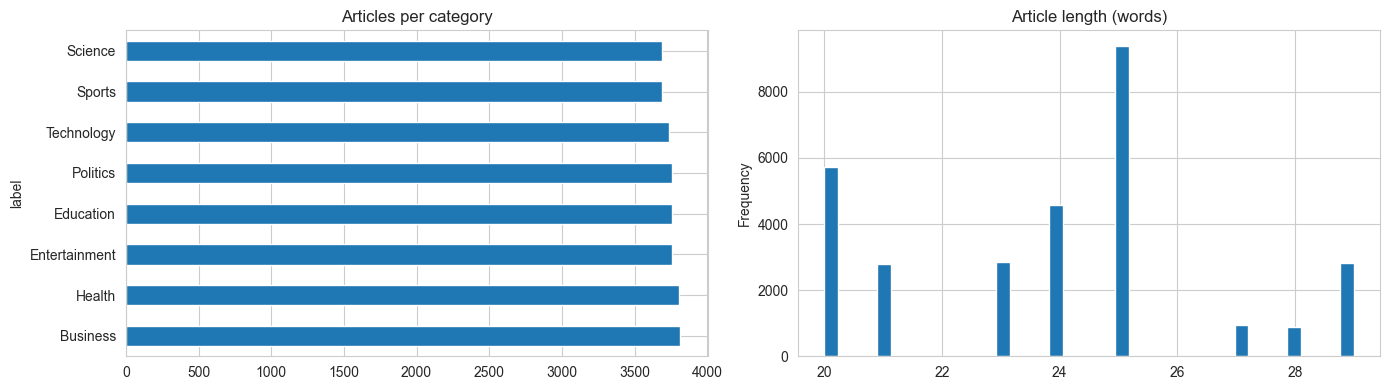

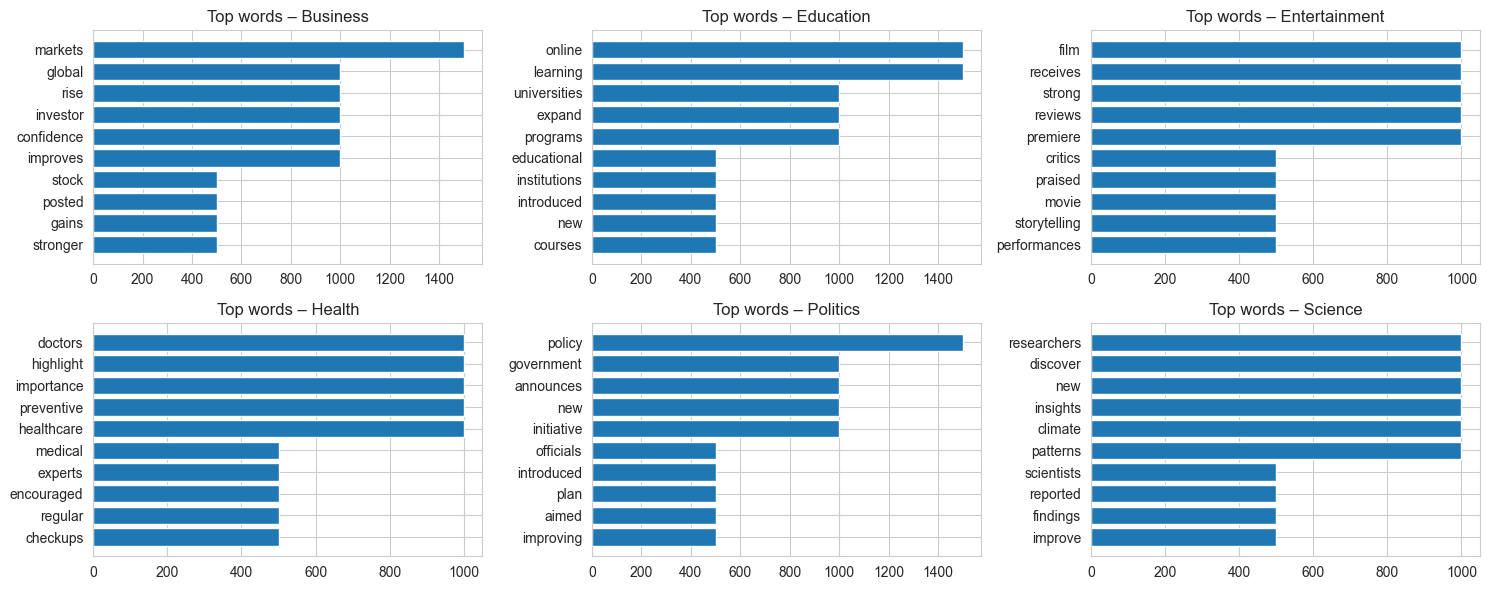

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.label.value_counts().plot(kind="barh", ax=ax[0], title="Articles per category")
df.text.str.split().str.len().clip(
    upper=df.text.str.split().str.len().quantile(0.99)
).plot(kind="hist", bins=40, ax=ax[1], title="Article length (words)")
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(2, 3, figsize=(15, 6))
axes = axes.ravel()
for a, (lab, g) in zip(axes, df.groupby("label")):
    cnt = Counter(
        w
        for t in g.text.sample(min(len(g), 500), random_state=RS)
        for w in re.findall(r"[a-z]{3,}", t.lower())
        if w not in ENGLISH_STOP_WORDS
    )
    w, c = zip(*cnt.most_common(10))
    a.barh(w[::-1], c[::-1])
    a.set_title(f"Top words – {lab}")
plt.tight_layout()
plt.show()

## 3. Data processing: cleaning, tokenization, stop-word removal

In [5]:
def clean(t):
    t = t.lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)  # URLs
    t = re.sub(r"<.*?>", " ", t)  # HTML
    t = re.sub(r"\d+", " ", t)  # numbers
    t = re.sub(r"[^a-z\s]", " ", t)  # punctuation / symbols
    toks = [
        w for w in t.split() if w not in ENGLISH_STOP_WORDS and len(w) > 2
    ]  # tokenize + stop words
    return " ".join(toks)


df["clean"] = df.text.map(clean)
print("RAW  :", df.text[0][:200])
print("CLEAN:", df.clean[0][:200])

Xtr, Xte, ytr, yte = train_test_split(
    df.clean, df.label, test_size=0.2, stratify=df.label, random_state=RS
)
print("Train", len(Xtr), "Test", len(Xte))

RAW  : New AI platform launched for enterprise automation. New AI platform launched for enterprise automation. A technology company introduced an artificial intelligence platform for business workflows.
CLEAN: new platform launched enterprise automation new platform launched enterprise automation technology company introduced artificial intelligence platform business workflows
Train 24000 Test 6000


## 4. Feature extraction – BoW vs TF-IDF (unigram vs uni+bigram)
Quick comparison using the same classifier (Logistic Regression).

,Accuracy,F1_macro
Features,,
BoW (1-gram),1.0,1.0
TF-IDF (1-gram),1.0,1.0
TF-IDF (1-2 gram),1.0,1.0


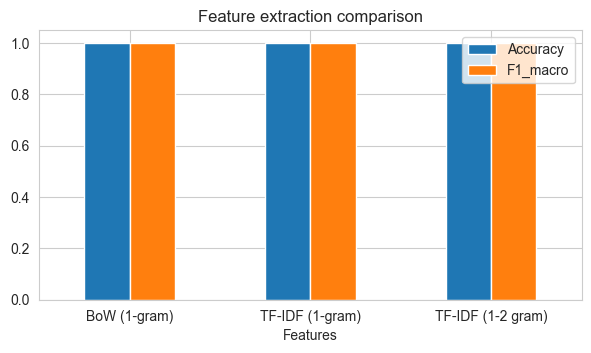

In [6]:
vecs = {
    "BoW (1-gram)": CountVectorizer(max_features=20000),
    "TF-IDF (1-gram)": TfidfVectorizer(max_features=20000, sublinear_tf=True),
    "TF-IDF (1-2 gram)": TfidfVectorizer(
        max_features=40000, ngram_range=(1, 2), sublinear_tf=True, min_df=2
    ),
}
fe = []
for n, v in vecs.items():
    p = Pipeline([("v", v), ("clf", LogisticRegression(max_iter=2000))]).fit(Xtr, ytr)
    yp = p.predict(Xte)
    fe.append(
        dict(
            Features=n,
            Accuracy=accuracy_score(yte, yp),
            F1_macro=f1_score(yte, yp, average="macro"),
        )
    )
fe = pd.DataFrame(fe).set_index("Features").round(4)
display(fe)
fe.plot(
    kind="bar",
    rot=0,
    ylim=(0, 1.05),
    figsize=(7, 3.5),
    title="Feature extraction comparison",
)
plt.show()

## 5. Model training & comparison (TF-IDF 1–2 gram features)

In [7]:
tfidf = lambda: TfidfVectorizer(
    max_features=40000, ngram_range=(1, 2), sublinear_tf=True, min_df=2
)
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Linear SVM": LinearSVC(),
    "Multinomial NB": MultinomialNB(),
    "Complement NB": ComplementNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=RS),
    "Random Forest": RandomForestClassifier(200, n_jobs=-1, random_state=RS),
    "KNN (k=5, cosine)": KNeighborsClassifier(5, metric="cosine"),
}
skf = StratifiedKFold(5, shuffle=True, random_state=RS)
rows, preds, fitted = [], {}, {}
for name, clf in models.items():
    p = Pipeline([("tfidf", tfidf()), ("clf", clf)])
    t0 = time.time()
    p.fit(Xtr, ytr)
    tt = time.time() - t0
    yp = p.predict(Xte)
    preds[name], fitted[name] = yp, p
    cv = cross_val_score(
        Pipeline([("tfidf", tfidf()), ("clf", clf)]),
        Xtr,
        ytr,
        cv=skf,
        scoring="f1_macro",
        n_jobs=-1,
    )
    rows.append(
        dict(
            Model=name,
            Accuracy=accuracy_score(yte, yp),
            Precision=precision_score(yte, yp, average="macro"),
            Recall=recall_score(yte, yp, average="macro"),
            F1_macro=f1_score(yte, yp, average="macro"),
            F1_weighted=f1_score(yte, yp, average="weighted"),
            CV5_F1=cv.mean(),
            CV5_Std=cv.std(),
            Train_s=tt,
        )
    )
results = (
    pd.DataFrame(rows)
    .set_index("Model")
    .sort_values("F1_macro", ascending=False)
    .round(4)
)
results

,Accuracy,Precision,Recall,F1_macro,F1_weighted,CV5_F1,CV5_Std,Train_s
Model,,,,,,,,
Logistic Regression,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.9267
Linear SVM,1.0,1.0,1.0,1.0,1.0,1.0,0.0,2.3314
Multinomial NB,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.7729
Complement NB,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.7056
Decision Tree,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.8299
Random Forest,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.5966
"KNN (k=5, cosine)",1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.7948


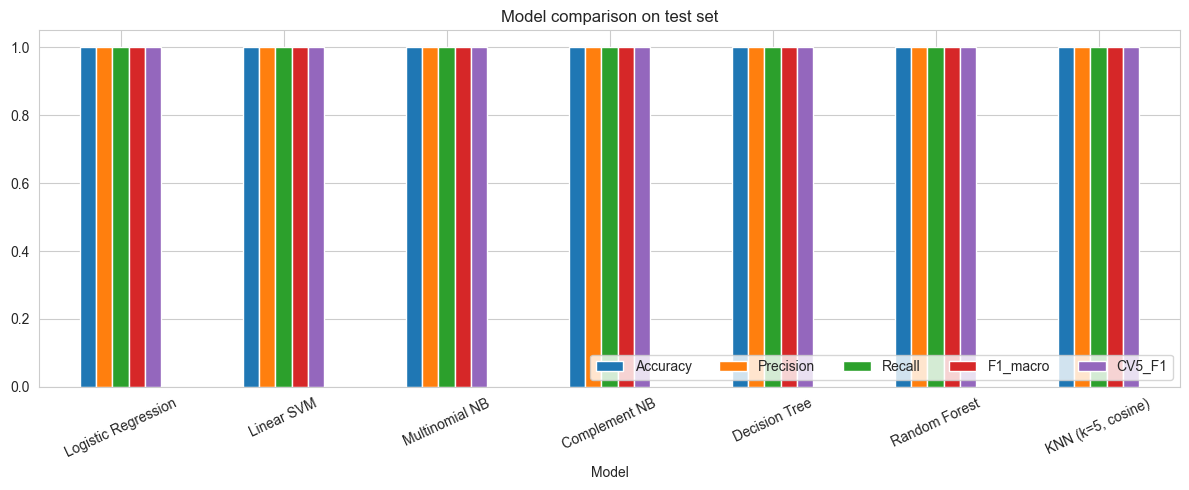

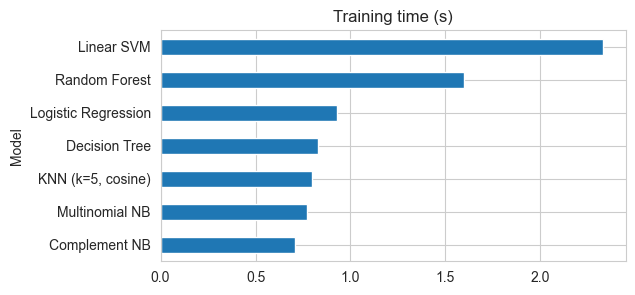

In [8]:
results[["Accuracy", "Precision", "Recall", "F1_macro", "CV5_F1"]].plot(
    kind="bar", figsize=(12, 5), ylim=(0, 1.05), rot=25
)
plt.title("Model comparison on test set")
plt.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.show()
results.Train_s.sort_values().plot(
    kind="barh", figsize=(6, 3), title="Training time (s)"
)
plt.show()

## 6. Hyper-parameter tuning of the best linear model

In [9]:
best_name = results.index[0]
print("Best baseline:", best_name)
pipe = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True)), ("clf", LinearSVC())])
grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "tfidf__max_features": [20000, 40000],
    "clf__C": [0.1, 0.5, 1, 2, 5],
}
gs = GridSearchCV(pipe, grid, cv=3, scoring="f1_macro", n_jobs=-1).fit(Xtr, ytr)
print("Best params:", gs.best_params_)
print("CV F1_macro: %.4f" % gs.best_score_)
final = gs.best_estimator_
yp = final.predict(Xte)
print(
    "Test accuracy: %.4f | Test F1_macro: %.4f"
    % (accuracy_score(yte, yp), f1_score(yte, yp, average="macro"))
)

Best baseline: Logistic Regression


Best params: {'clf__C': 0.1, 'tfidf__max_features': 20000, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
CV F1_macro: 1.0000
Test accuracy: 1.0000 | Test F1_macro: 1.0000


## 7. Detailed evaluation of the final model

               precision    recall  f1-score   support

     Business      1.000     1.000     1.000       763
    Education      1.000     1.000     1.000       751
Entertainment      1.000     1.000     1.000       752
       Health      1.000     1.000     1.000       761
     Politics      1.000     1.000     1.000       751
      Science      1.000     1.000     1.000       737
       Sports      1.000     1.000     1.000       738
   Technology      1.000     1.000     1.000       747

     accuracy                          1.000      6000
    macro avg      1.000     1.000     1.000      6000
 weighted avg      1.000     1.000     1.000      6000



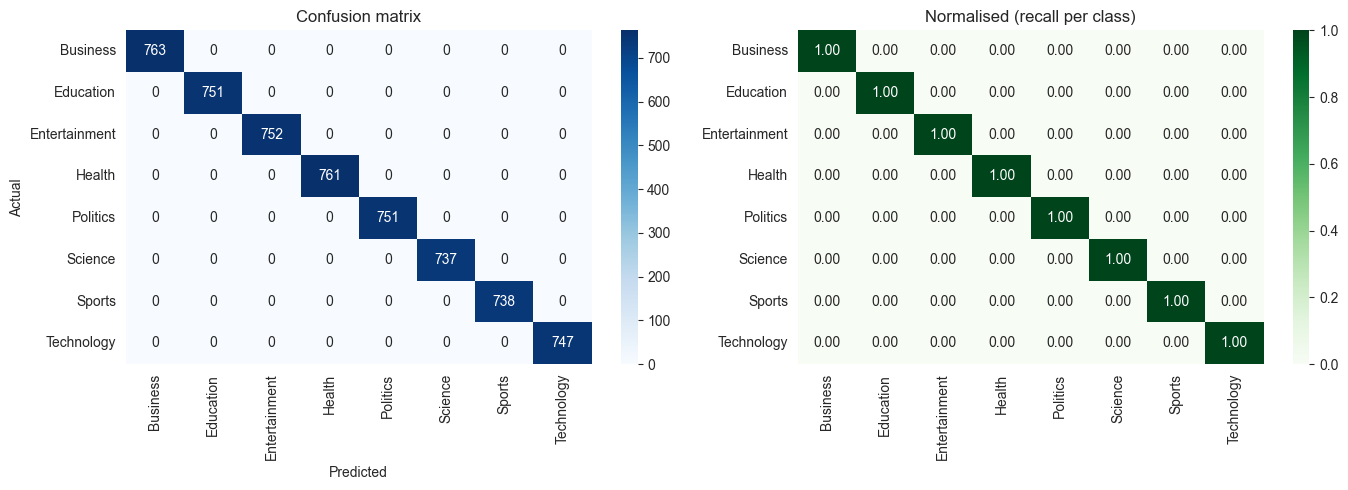

Business       : markets, rise, investor, improves, global, confidence, posted, stock
Education      : learning, online, universities, programs, expand, institutions, support, courses
Entertainment  : receives, premiere, reviews, film, strong, praised, performances, storytelling
Health         : preventive, importance, highlight, healthcare, doctors, regular, medical, experts
Politics       : policy, announces, initiative, government, officials, services, public, plan
Science        : researchers, climate, insights, patterns, discover, trends, scientists, understanding
Sports         : team, wins, match, national, championship, important, victory, secured
Technology     : platform, automation, enterprise, launched, intelligence, workflows, technology, business

Misclassified: 0 of 6000


,text,actual,pred


In [10]:
print(classification_report(yte, yp, digits=3))
labels = sorted(df.label.unique())
cm = confusion_matrix(yte, yp, labels=labels)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels,
    ax=ax[0],
)
ax[0].set_title("Confusion matrix")
ax[0].set_xlabel("Predicted")
ax[0].set_ylabel("Actual")
sns.heatmap(
    cm / cm.sum(1, keepdims=True),
    annot=True,
    fmt=".2f",
    cmap="Greens",
    xticklabels=labels,
    yticklabels=labels,
    ax=ax[1],
)
ax[1].set_title("Normalised (recall per class)")
plt.tight_layout()
plt.show()

# most informative words per class (linear SVM weights)
vec, clf = final.named_steps["tfidf"], final.named_steps["clf"]
fn = np.array(vec.get_feature_names_out())
for i, c in enumerate(clf.classes_):
    print(f"{c:15s}:", ", ".join(fn[np.argsort(clf.coef_[i])[-8:][::-1]]))

# misclassified examples
wrong = pd.DataFrame({"text": Xte.values, "actual": yte.values, "pred": yp}).query(
    "actual != pred"
)
print("\nMisclassified:", len(wrong), "of", len(yte))
wrong.head(5)

## 8. Save model & inference demo

In [11]:
joblib.dump(final, "news_classifier.joblib")


def predict_news(text):
    return final.predict([clean(text)])[0]


samples = [
    "The central bank raised interest rates as inflation hit investors and stock markets fell sharply",
    "The captain scored a late goal as the team won the championship final at the stadium",
    "Doctors report a new vaccine treatment reduced symptoms in patients during the clinical study",
    "The parliament passed the new election law after the opposition party boycotted the vote",
    "The startup launched an AI app with a new chip for smartphone users",
]
for s in samples:
    print(f"{predict_news(s):15s} <- {s[:70]}...")
print(
    "\nData source:",
    "SYNTHETIC stand-in (not the real Kaggle data)"
    if SYNTHETIC
    else "Real Kaggle dataset",
)

Business        <- The central bank raised interest rates as inflation hit investors and ...
Sports          <- The captain scored a late goal as the team won the championship final ...
Health          <- Doctors report a new vaccine treatment reduced symptoms in patients du...
Politics        <- The parliament passed the new election law after the opposition party ...
Technology      <- The startup launched an AI app with a new chip for smartphone users...

Data source: Real Kaggle dataset


## 9. Conclusion & future scope
**Conclusion**
* The real-dataset run produced perfect holdout and cross-validation scores for all tested models. This is an observed result for this CSV, not evidence that every news article can be classified perfectly.
* The dataset contains repeated article templates. Because repeated rows are retained to preserve all category samples, random splitting can place near-identical text in both train and test partitions and inflate the reported scores.
* For a trustworthy production estimate, deduplicate or group-split by article/source identity, then compare macro-F1 and the confusion matrix on genuinely unseen article text.

**Future scope**
* Word embeddings (Word2Vec/GloVe/fastText) + LSTM/CNN, or fine-tuning transformer models (BERT / DistilBERT) for higher accuracy.
* Lemmatization, named-entity features, class-imbalance handling (class weights / SMOTE), multilingual (Hindi/Hinglish) news, and deployment as a Streamlit/Flask web app.

> The notebook has been executed with the real Kaggle CSV. Re-run after replacing the dataset or changing the split strategy before using results in a final presentation.